# 14 モンテカルロ法

ここでは**モンテカルロ法**について学びます。モンテカルロ法は乱数を用いて確率的に数値計算を行う方法の総称です。（解析的に解けない）積分計算、物理現象、金融現象、生物現象、統計的推測に至るまで、解析的な手法が及ばない諸現象に幅広く用いられており、計算機能力の向上とともにその有用性が確立されてきました。

**【数理工学のポイント：なぜ高次元問題でモンテカルロ法を使うのか？】**  
第06回で学んだ台形法（誤差 $O(N^{-2})$）やシンプソン法（誤差 $O(N^{-4})$）などの格子点に基づく数値積分は、1次元では非常に高速に収束します。しかし、次元 $d$ が大きくなると必要な格子点数が $N^d$ と爆発的に増大します（**次元の呪い**）。  
これに対し、モンテカルロ法の誤差収束は $O(N^{-1/2})$ と緩やかであるものの、**収束速度が次元 $d$ に依存しない**という大きな利点があり、統計力学の多体問題や金融工学の高次元積分などで威力を発揮します。

## 14.1 乱数の発生と使い方

Pythonでは疑似乱数を生成する方法はいくつか存在し、**randomモジュール**、**numpy.randomモジュール**、**scipy.statsモジュール**などが存在します。最も高機能なものはscipy.statsモジュールですが、ここでは比較的使いやすいnumpy.randomモジュールを使います。

In [1]:
import numpy as np

# 乱数のseed（種）の設定
np.random.seed(1)

# 範囲[0, 1)の一様分布から1つ乱数を生成する。
print(np.random.rand())

0.417022004702574


乱数をnumpy.array(Numpy配列)の形で出力することもできます。

In [2]:
import numpy as np

# 乱数のseed（種）の設定
np.random.seed(1)

# 範囲[0, 1)の一様分布から乱数配列（Numpy配列）を生成する。
print(np.random.rand(10))
# 多次元配列として出力することも可能
print(np.random.rand(2,3))

[4.17022005e-01 7.20324493e-01 1.14374817e-04 3.02332573e-01
 1.46755891e-01 9.23385948e-02 1.86260211e-01 3.45560727e-01
 3.96767474e-01 5.38816734e-01]
[[0.41919451 0.6852195  0.20445225]
 [0.87811744 0.02738759 0.67046751]]


### 乱数のseed（種）の設定

コンピュータ内において乱数とはあくまで**疑似乱数**です。要するに乱数を計算する式に基づいて乱数を出力しているのです。その際、乱数を計算する式に初期値を決める必要があります。典型的な例は**線形合同法**と呼ばれる下記の式に従う疑似乱数発生方法です。  

\begin{equation}
x_{i+1}=ax_i+b \hspace{1cm}\pmod{m}, \hspace{1cm} 0\leq x_i <m
\end{equation}

$a,b,m$は整数であり、$x_0$をユーザーが決めるとこの式に従い乱数が生成される仕組みです。もちろん、上手に$a,b,m$を設定することが重要であり、それにより疑似乱数の周期が決まります。上式の$x_0$のようにユーザー側で設定する必要がある初期値のことを**乱数の種（seed）**と言います。乱数を使う場合には必ずseedを設定することを忘れないで下さい。`numpy.random`においてseedを設定するには下記のように`random.seed()`メソッドを用います。引数にseedを設定します。seedとしてはintもしくはnumpy配列（intの値）が使えます。詳しくは[`numpy.random.seed`](https://docs.scipy.org/doc/numpy/reference/generated/numpy.random.seed.html#numpy.random.seed)を参照してください。  
モンテカルロ法では初期値を数多く取り繰り返し計算機実験を実行することになります。そこで、下記では`for`ループ共に乱数を使う典型的な例を載せてます。

In [3]:
#乱数をループと共に使う場合のテンプレート

import numpy as np
""" 乱数のseed（種）の設定"""
np.random.seed(1)

for i in range(10):
    """ループ内での乱数の使用"""
    print(np.random.rand())

0.417022004702574
0.7203244934421581
0.00011437481734488664
0.30233257263183977
0.14675589081711304
0.0923385947687978
0.1862602113776709
0.34556072704304774
0.39676747423066994
0.538816734003357


異なったサンプルを数多く取りたい場合、下記は典型的なダメな例です。ループ内でseedを設定しているので乱数としてすべて同じ値を出力してしまってます。

In [4]:
import numpy as np

for i in range(10):
    """ループ内での乱数の使用"""
    np.random.seed(1)
    print(np.random.rand())

0.417022004702574
0.417022004702574
0.417022004702574
0.417022004702574
0.417022004702574
0.417022004702574
0.417022004702574
0.417022004702574
0.417022004702574
0.417022004702574


さて、このような一様乱数の確率密度分布をグラフとして出力してみましょう。グラフについてはmatplotlibを用います（情報処理の講義でやった[このページ](http://kino.sub.jp/IT2015_old/IT_06.html)も参考にしてください）。

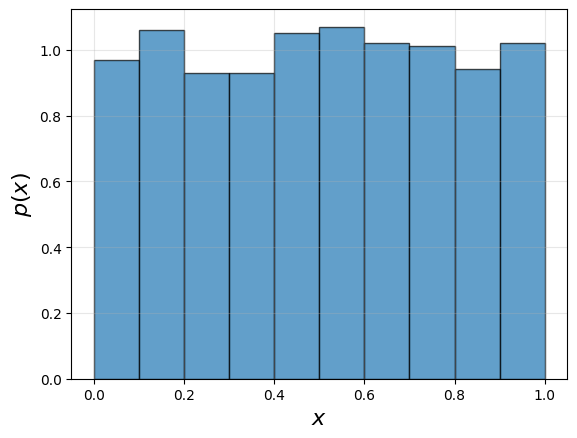

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(1)

# 生成する乱数のサイズ
size = 1000
# 一様分布から乱数配列を生成
uni = np.random.rand(size)

# [0, 1)区間の分割数
bins = 10
# x軸の範囲を指定
x_range = (0, 1)
# 確率密度の表示形式を指定（density=True は積分値が1になる正規化を表す）
plt.hist(uni, bins, range=x_range, density=True, edgecolor="black", alpha=0.7)
plt.xlabel(r"$x$", fontsize=16)
plt.ylabel(r"$p(x)$", fontsize=16)
plt.grid(alpha=0.3)
plt.show()

`numpy.random`モジュールでは様々な確率密度関数に従う乱数を生成できます。詳細は[マニュアル](https://docs.scipy.org/doc/numpy/reference/routines.random.html)を調べて下さい。

### 問題
上記の要領で正規分布に従う乱数の確率分布をグラフで表示せよ。  

\begin{equation}
\displaystyle{p(x)=\frac{1}{\sqrt{2\pi\sigma^2}}\exp{\left(-\frac{(x-\mu)^2}{2\sigma^2}\right)}}
\end{equation}

正規分布に従う乱数を出力するメソッドは次の通りである。  
`np.random.normal(mu, sigma, size)`  
ここで`mu`は平均$\mu$、`sigma`は標準偏差$\sigma$である。
生成する乱数のサイズは100000、分割数（棒の数）は100とし、$\mu=0$、$\sigma=1$としなさい。

## 14.2 中心極限定理

確率論の最も重要な定理の一つである「**中心極限定理**」を数値実験で視覚化してみましょう。中心極限定理の数学的な表現は次の通りです。

**（実用的な）中心極限定理**  
$X_1, X_2, \dots, X_n$ を同一の確率分布（ただし，平均 $\mu$，分散 $\sigma^2$ が有限）に従う独立な確率変数とする．このとき，$X_1, X_2, \dots, X_n$ の標本平均
$$
S_n = \frac{1}{n}(X_1 + X_2 + \dots + X_n)
$$
に対して，平均 $0$・分散 $1$ に標準化した確率変数
$$
Z_n = \frac{\sqrt{n}}{\sigma}(S_n - \mu)
$$
を考える．このとき，$Z_n$ の確率分布 $f_n$ は $n \to \infty$ で標準正規分布 $\mathcal{N}(0, 1)$ に収束する：
$$
\lim_{n \to \infty} f_n(x) = \frac{1}{\sqrt{2\pi}} \exp\left(-\frac{x^2}{2}\right)
$$

この定理の意味は「**元の確率分布がどのような形（一様分布や歪んだベータ分布など）であっても、独立な確率変数の標本平均を標準化したものは $n \to \infty$ の極限で標準正規分布に従う**」ということです。

### 【事前準備】グラフの日本語表示設定
`matplotlib` は初期状態では日本語フォントに対応していないため、グラフ内の日本語が文字化け（豆腐 `□□□` 表示）します。以下のセルを実行して日本語表示を有効にしてください。

In [ ]:
# 日本語表示用パッケージのインストール（初回のみ実行されます）
!pip install matplotlib-fontja

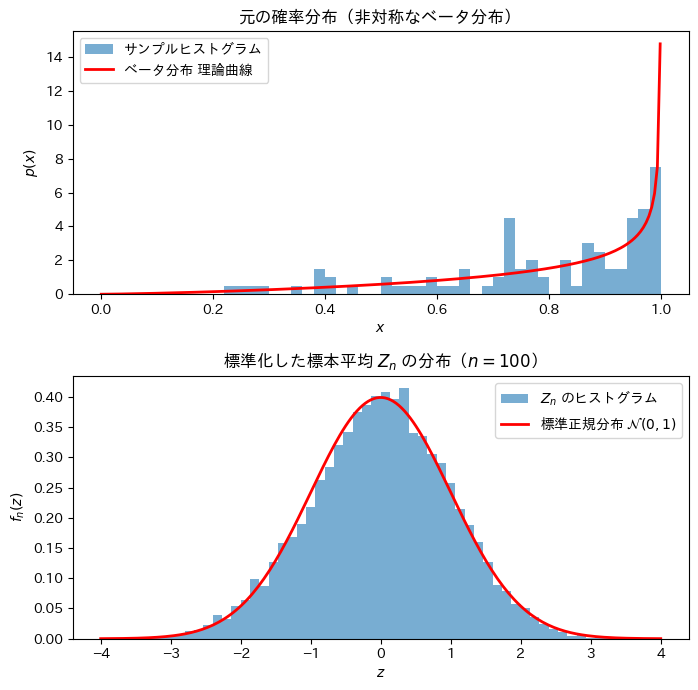

In [4]:
# 中心極限定理のシミュレーション
import numpy as np
import scipy.stats as sc_st
import matplotlib.pyplot as plt
import matplotlib_fontja

# 試行回数（サンプル数）
sample = 10000
# 各試行での乱数生成数 n
n_size = 100
# 各試行の標本平均を格納する配列
s = np.zeros(sample)

# 非対称なベータ分布のパラメータ設定
a, b = 2.31, 0.627
# ベータ分布の理論平均と理論標準偏差
mu_theory = a / (a + b)
sigma_theory = np.sqrt((a * b) / ((a + b)**2 * (a + b + 1)))

# 各試行で n_size 個の乱数を生成し、その平均を s に格納
for k in range(sample):
    np.random.seed(k)
    r = sc_st.beta.rvs(a, b, size=n_size)
    s[k] = r.mean()

# 定理の式通りに標準化 Z_n = sqrt(n) * (S_n - mu) / sigma を計算
z = np.sqrt(n_size) * (s - mu_theory) / sigma_theory

# グラフ描画（上段：元のベータ分布、下段：標準化された標本平均の分布）
fig, ax = plt.subplots(2, 1, figsize=(7, 7))

# 上段：元の分布（非対称な形）
x_beta = np.linspace(0.001, 0.999, 200)
ax[0].hist(r, range=(0, 1), bins=50, density=True, alpha=0.6, label="サンプルヒストグラム")
ax[0].plot(x_beta, sc_st.beta.pdf(x_beta, a, b), "r-", lw=2, label="ベータ分布 理論曲線")
ax[0].set_title("元の確率分布（非対称なベータ分布）")
ax[0].set_xlabel(r"$x$")
ax[0].set_ylabel(r"$p(x)$")
ax[0].legend()

# 下段：標準化した標本平均 Z_n の分布（標準正規分布に一致）
x_norm = np.linspace(-4, 4, 200)
ax[1].hist(z, range=(-4, 4), bins=60, density=True, alpha=0.6, label=r"$Z_n$ のヒストグラム")
ax[1].plot(x_norm, sc_st.norm.pdf(x_norm, 0, 1), "r-", lw=2, label=r"標準正規分布 $\mathcal{N}(0, 1)$")
ax[1].set_title(rf"標準化した標本平均 $Z_n$ の分布（$n={n_size}$）")
ax[1].set_xlabel(r"$z$")
ax[1].set_ylabel(r"$f_n(z)$")
ax[1].legend()

plt.tight_layout()
plt.show()

## 14.3 サイコロの作成

乱数を使ってサイコロ（正6面体）を作ってみましょう。使いまわしできるように下記のように関数化して下さい。

In [10]:
import numpy as np

def dice(num=6):
    return int(num*np.random.rand()+1)

if __name__=='__main__':
    np.random.seed(1)
    for i in range(10):
        print(dice())

3
5
1
2
1
1
2
3
3
4


### 問題（大数の法則の確認）
サイコロを $T = 2^1, 2^2, \dots, 2^{14}$ 回振るシミュレーションを行い、1の目が出る相対度数（経験確率）を片対数グラフでプロットしなさい。（X軸：試行回数 $T$（対数スケール）、Y軸：1の目が出る割合 $P(1)$、理論値 $1/6$ の水平線も重ねて表示すること）

### 【追加演習 14.1】モンテカルロ法による円周率 $\pi$ の推定と誤差収束
モンテカルロ法の代表的な応用である数値積分の例として、円周率 $\pi$ の近似値を求めてみましょう。

第1象限の単位正方形 $[0, 1] \times [0, 1]$ 内に $N$ 個の一様乱数点 $(x_i, y_i)$ をランダムに発生させます。このうち、単位円の内部（$x_i^2 + y_i^2 \le 1$）に入る点の個数を $N_{\text{in}}$ とすると、面積比から円周率 $\pi$ は次のように推定できます。
$$
\hat{\pi} = 4 \times \frac{N_{\text{in}}}{N}
$$

1. サンプル数 $N = 10^1, 10^2, 10^3, 10^4, 10^5, 10^6$ について $\hat{\pi}$ を計算し、真値 `np.pi` との絶対誤差 $|\hat{\pi} - \pi|$ を求めなさい。
2. 横軸をサンプル数 $N$、縦軸を絶対誤差 $|\hat{\pi} - \pi|$ とした両対数グラフ（`log-log` プロット）を描画し、誤差が理論的な収束速度 $O(1/\sqrt{N})$（傾き $-1/2$）に沿って減少することを確認しなさい。

In [ ]:
# 追加演習 14.1：モンテカルロ法による円周率の推定（ひな形）
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)
N_list = [10**k for k in range(1, 7)]
errors = []

for N in N_list:
    # [0, 1) の一様乱数を N 個ずつ生成
    x = np.random.rand(N)
    y = np.random.rand(N)
    
    # 【穴埋め 1】単位円内 (x^2 + y^2 <= 1) に入る点の数をカウント
    # n_in = ...
    
    # 【穴埋め 2】円周率の推定値 pi_est と真値 np.pi との絶対誤差 err を計算
    # pi_est = ...
    # err = ...
    
    errors.append(err)
    print(f"N = {N:7d} | 推定値 = {pi_est:.6f} | 絶対誤差 = {err:.6e}")

# 両対数グラフの描画
plt.figure(figsize=(6, 4))
plt.loglog(N_list, errors, "o-", label="モンテカルロ推定誤差")
plt.loglog(N_list, 1.0 / np.sqrt(N_list), "--", color="gray", label=r"理論収束オーダー $O(N^{-1/2})$")
plt.xlabel(r"サンプル数 $N$", fontsize=14)
plt.ylabel(r"絶対誤差 $|\hat{\pi} - \pi|$", fontsize=14)
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.show()

## 14.4 1Dランダムウォーク

それでは**ランダムウォーク**のシミュレーションを行ってみよう。ランダムウォークとはその名の通りランダムに歩き回る運動のことです。有名なランダムウォークとして花粉の中の微粒子が水面上でランダムウォークすることが知られています（ブラウン運動とも言います）。この微粒子の運動はペランが実験を行い観察し理論的な考察はアインシュタインが行いました。ランダムウォークは花粉微粒子の運動、株価の時系列、バクテリアの運動に至るまで様々な現象の基礎的なモデルとして取り扱われます。  


In [12]:
import numpy as np

if __name__=='__main__':
    t=10
    x=0
    for i in range(t):
        if int(np.random.rand()*2)==0:
            x+=1
        else:
            x-=1
        print(x)

1
2
3
2
1
2
3
4
3
4


### 14.4.1 1Dランダムウォークの統計的性質

数列だけでは良く分からないので、それでは1Dランダムウォークの動きの時系列をグラフで見てみましょう。

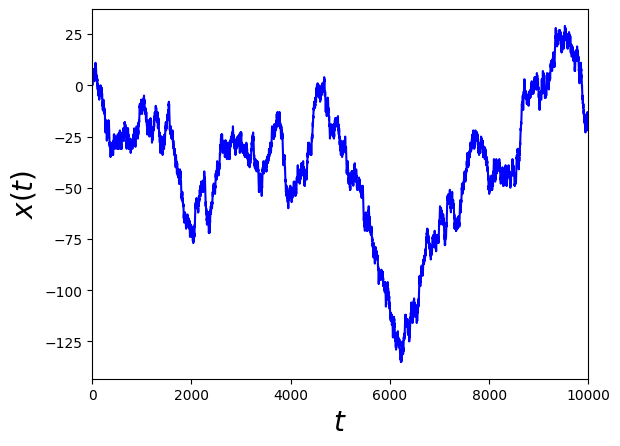

In [12]:
import numpy as np

if __name__=='__main__':
    t=10000
    x=0
    time=[]
    series=[]
    np.random.seed(1)
    for i in range(t):
        if int(np.random.rand()*2)==0:
            x+=1
        else:
            x-=1
        time.append(i+1)
        series.append(x)
 
    plt.xlabel("$t$", fontsize="20")
    plt.ylabel("$x(t)$", fontsize="20")
    plt.xlim([0, 10e+3])
    plt.plot(time, series, "-b")
    #print(series)

### 問題
1つのサンプルだけの動きを見ても良く分からないので、サンプル数を増やして時系列を重ね書きします。このとき各サンプルごとにseedを変更することに注意してください（同じ初期値から始めると同じ時系列が生成されることになります）。

#### (1) 拡散則（原点からの距離と時間の平方根則）
上のグラフを見ると、1Dランダムウォークはステップ数 $t$ が大きくなるにつれて原点から離れていく傾向がありそうです。

各ステップで $+1$ または $-1$ に等確率で移動する場合、$t$ ステップ後の位置 $x(t)$ の平均は $\langle x(t) \rangle = 0$ ですが、分散（二乗平均距離）は
$$
\langle x(t)^2 \rangle = t
$$
となり、ステップ数 $t$ に比例します。また、$t$ が十分大きいとき $x(t)$ は中心極限定理により正規分布 $\mathcal{N}(0, t)$ に従うため、原点からの平均距離 $\langle R(t) \rangle = \langle |x(t)| \rangle$ は時間の平方根 $\sqrt{t}$ に比例します（**拡散則**）：
$$
\langle R(t) \rangle = \langle |x(t)| \rangle \approx \sqrt{\frac{2}{\pi} t} \approx 0.7979\sqrt{t}
$$
（※この性質は、連続極限における**拡散方程式（熱伝導方程式）** $\frac{\partial u}{\partial t} = D \frac{\partial^2 u}{\partial x^2}$ の解の広がり方と本質的に同じものです。）

本当にこの法則が成り立っているか、1000サンプルの平均をとって調べてみましょう。

[np.int64(2), np.int64(4), np.int64(8), np.int64(16), np.int64(32), np.int64(64), np.int64(128), np.int64(256), np.int64(512), np.int64(1024)]


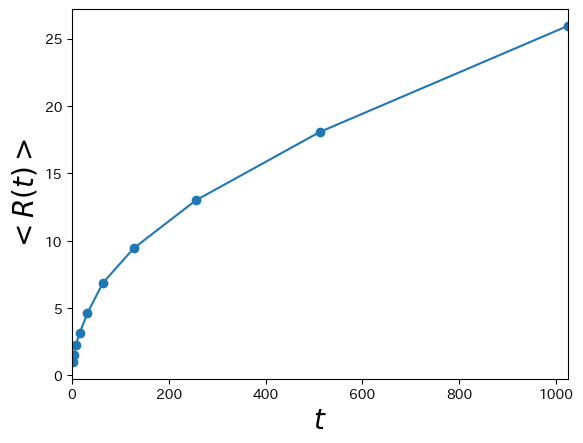

In [8]:
import numpy as np
import matplotlib.pyplot as plt

if __name__=='__main__':
    p_ex=10
    t_max=np.power(2, p_ex)
    sample=1000
    distance=np.zeros((p_ex, sample))

    for j in range(sample):
        x=0
        np.random.seed(j+1)
        count=1
        for i in range(t_max):
            if int(np.random.rand()*2)==0:
                x+=1
            else:
                x-=1
            if i==np.power(2,count)-1:
                distance[count-1][j]=x
                count+=1

    av_dis=[np.average(np.abs(distance[i])) for i in range(0, p_ex)]
    
    x_axis=[np.power(2, i) for i in range(1, p_ex+1)]
    print(x_axis)
    
    plt.plot(x_axis, av_dis, "o-")
    plt.xlabel("$t$", fontsize="20")
    plt.ylabel("$<R(t)>$", fontsize="20")
    plt.xlim([0,1024])
    
    #plt.axis([0, t_max,0,30])
    #plt.xscale("log")
    #plt.yscale("log")
    #print(x_axis)
    #plt.plot(x_axis, y_axis, "-")
    plt.show()
    #print(av_dis)
    

### 【追加演習 14.2】拡散則の理論曲線との比較・両対数プロット検証
上で計算した `x_axis`（時刻 $t$）および `av_dis`（シミュレーションによる平均距離 $\langle R(t) \rangle$）を用いて、以下の2つを実行しなさい。

1. 通常の線形スケールグラフにおいて、シミュレーション結果 `av_dis` に理論曲線 $y(t) = \sqrt{\frac{2}{\pi}t}$ を重ねてプロットし、両者がよく一致することを確認しなさい。
2. 両対数グラフ（`plt.xscale("log")`, `plt.yscale("log")`）で描画し、グラフが傾き $1/2$ の直線になることを確認しなさい。

#### (2) レヴィの逆正弦法則（Arcsine law）
次に、1Dランダムウォークを $T = 1000$ ステップ行ったとき、 **「全時間の何割をプラス側（$x > 0$）で過ごしたか（滞在時間割合 $t_d \in [0, 1]$）」** の確率分布を調べてみましょう。

素朴な直感では「プラスとマイナスに半分ずつ行くので、$t_d = 0.5$ 付近が最も多くなる（山型の分布になる）」と予想しがちです。しかし実際には、一度どちらかの領域へ大きく踏み込むと原点へ戻るのに時間がかかるため、 **$t_d \approx 0$（ずっとマイナス側）や $t_d \approx 1$（ずっとプラス側）に集中するU字型の分布** になります。

この直感に反する現象は確率論で **逆正弦法則（Arcsine law）** と呼ばれ、極限の確率密度関数は次の式で表されます。
$$
p(x) = \frac{1}{\pi \sqrt{x(1 - x)}} \quad (0 < x < 1)
$$

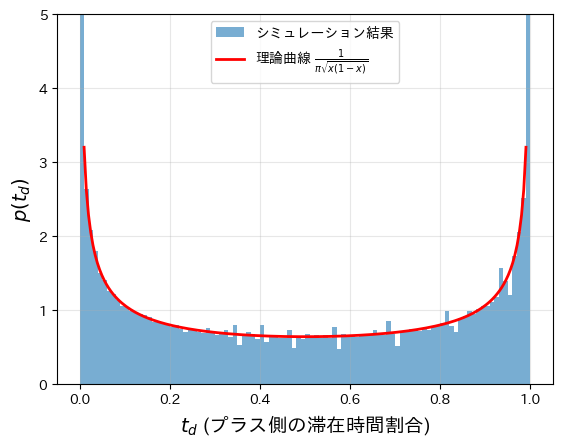

In [10]:
# 逆正弦法則のシミュレーションと理論曲線の比較
import numpy as np
import matplotlib.pyplot as plt

sample = 100000
t_max = 1000
dtime = np.zeros(sample)

for i in range(sample):
    np.random.seed(i)
    x = [0, 0]
    count_pos = 0
    for t in range(t_max):
        if int(np.random.rand() * 2) == 0:
            x[1] = x[0] + 1
        else:
            x[1] = x[0] - 1
        if x[0] + x[1] > 0:
            count_pos += 1
        x[0] = x[1]
    dtime[i] = count_pos / t_max

# ヒストグラムと逆正弦法則の理論曲線を描画
bins = 100
plt.hist(dtime, bins=bins, range=(0, 1), density=True, alpha=0.6, label="シミュレーション結果")

x_arc = np.linspace(0.01, 0.99, 200)
p_arc = 1.0 / (np.pi * np.sqrt(x_arc * (1.0 - x_arc)))
plt.plot(x_arc, p_arc, "r-", lw=2, label=r"理論曲線 $\frac{1}{\pi\sqrt{x(1-x)}}$")

plt.xlabel(r"$t_d$ (プラス側の滞在時間割合)", fontsize=14)
plt.ylabel(r"$p(t_d)$", fontsize=14)
plt.ylim([0, 5])
plt.grid(alpha=0.3)
plt.legend()
plt.show()

### 14.4.2 1Dランダムウォークのアニメーションと境界条件
ここからは第08回で学んだ `pygame` を用いて、1次元グリッド（$21$ マス、座標 $x \in \{0, 1, \dots, 20\}$）上のランダムウォークをアニメーションで可視化します。

シミュレーションの領域端（$x=0$ および $x=20$）での振る舞いとして、次の2種類の境界条件を比較してみましょう。
1. **反射境界条件（壁で跳ね返る）:** 端にいる状態でさらに外側へ進もうとした場合、内側の隣マスへ跳ね返ります。
2. **周期境界条件（反対側から現れる）:** 右端（$x=20$）から右へ進むと左端（$x=0$）へ移動し、左端（$x=0$）から左へ進むと右端（$x=20$）へ移動します。

1Dランダムウォークのアニメーションを作成してみましょう。

In [1]:
import pygame
import numpy as np

if __name__=='__main__':
    BLACK = (0, 0, 0)
    WHITE = (255, 255, 255)
    GREEN = (0, 255, 0)
    RED = (255, 0, 0)
    
    pygame.init()
    WINDOW_SIZE=(500, 100)
    screen=pygame.display.set_mode(WINDOW_SIZE)
    
    #1次元グリッドの初期化
    row=21
    grid_x=20
    grid_y=20
    grid_x_ini=39
    grid_y_ini=39
        
    x=10 #初期座標
    np.random.seed(1) #乱数初期化用seed
    done=False #イベントループ用変数
    while not done:
        for event in pygame.event.get():  # User did something
            if event.type == pygame.QUIT:  # If user clicked close
                done = True  
        screen.fill(WHITE)
        
        if int(np.random.rand()*2)==0:
            x+=1
        else:
            x-=1
        
        for i in range(row):
            pygame.draw.rect(screen, BLACK, [grid_x_ini+i*20, grid_y_ini, grid_x, grid_y],1) 
            if i==x:
                pygame.draw.ellipse(screen, RED, [grid_x_ini+i*20, grid_y_ini, grid_x, grid_y])
                
        pygame.display.flip()
        pygame.time.delay(100)
    pygame.quit()
    

pygame 2.5.0 (SDL 2.28.0, Python 3.12.3)
Hello from the pygame community. https://www.pygame.org/contribute.html


境界条件を変えてみます。１反射境界条件２周期境界条件

In [11]:
# 1. 反射境界条件の1Dランダムウォーク
import pygame
import numpy as np

if __name__ == '__main__':
    BLACK = (0, 0, 0)
    WHITE = (255, 255, 255)
    RED = (255, 0, 0)

    pygame.init()
    WINDOW_SIZE = (500, 100)
    screen = pygame.display.set_mode(WINDOW_SIZE)
    pygame.display.set_caption("1D random walk (Reflecting Boundary)")
    clock = pygame.time.Clock()

    row = 21
    x = 10  # 初期座標（中央）
    np.random.seed(1)
    done = False

    while not done:
        for event in pygame.event.get():
            if event.type == pygame.QUIT:
                done = True

        screen.fill(WHITE)

        # 反射境界条件での座標更新
        if int(np.random.rand() * 2) == 0:
            if x != 20:
                x += 1
            else:
                x -= 1
        else:
            if x != 0:
                x -= 1
            else:
                x += 1

        for i in range(row):
            pygame.draw.rect(screen, BLACK, [39 + i * 20, 39, 20, 20], 1)
            if i == x:
                pygame.draw.ellipse(screen, RED, [39 + i * 20, 39, 20, 20])

        pygame.display.flip()
        clock.tick(10)  # 1秒間に10ステップ更新

    pygame.quit()

pygame 2.5.0 (SDL 2.28.0, Python 3.12.3)
Hello from the pygame community. https://www.pygame.org/contribute.html


In [12]:
# 2. 周期境界条件の1Dランダムウォーク
import pygame
import numpy as np

if __name__ == '__main__':
    BLACK = (0, 0, 0)
    WHITE = (255, 255, 255)
    RED = (255, 0, 0)

    pygame.init()
    WINDOW_SIZE = (500, 100)
    screen = pygame.display.set_mode(WINDOW_SIZE)
    pygame.display.set_caption("1D random walk (Periodic Boundary)")
    clock = pygame.time.Clock()

    row = 21
    x = 10  # 初期座標（中央）
    np.random.seed(1)
    done = False

    while not done:
        for event in pygame.event.get():
            if event.type == pygame.QUIT:
                done = True

        screen.fill(WHITE)

        # 周期境界条件での座標更新（剰余演算子 % を使っても1行で書ける）
        if int(np.random.rand() * 2) == 0:
            x = (x + 1) % row
        else:
            x = (x - 1) % row

        for i in range(row):
            pygame.draw.rect(screen, BLACK, [39 + i * 20, 39, 20, 20], 1)
            if i == x:
                pygame.draw.ellipse(screen, RED, [39 + i * 20, 39, 20, 20])

        pygame.display.flip()
        clock.tick(10)

    pygame.quit()

## 14.5 2Dランダムウォーク

続いて、1次元から平面上のランダムウォーク（**2Dランダムウォーク**）へ拡張しましょう。

---

### レポート課題（第09回）

2Dランダムウォークについて、以下の **【課題1】** および **【課題2】** に取り組み、Jupyter Notebook（`.ipynb`）にまとめて提出しなさい。

#### 【課題1】`pygame` による2Dランダムウォークのアニメーション実装
以下の仕様を満たす2Dランダムウォークのアニメーションプログラムを作成しなさい。
- **ウィンドウサイズ:** $500 \times 500$
- **グリッド数:** $21 \times 21$（座標 $x, y \in \{0, 1, \dots, 20\}$、初期位置は中央 $(10, 10)$）
- **移動ルール:** 1ステップごとに**上下左右の4方向へ等確率（各 $1/4$）** で1マス移動する。
  - **注意:** `if` と `elif` の条件式ごとに `np.random.rand()` を何度も呼び出すと確率が偏るバグの原因となるため、**1ステップにつき乱数を1回だけ生成して変数に格納** してから分岐させること。
- **境界条件:** 周期境界条件（上下左右の端を越えたら反対側から現れる）または反射境界条件のいずれかを実装すること。

#### 【課題2】2Dランダムウォークの拡散則の検証と考察
境界のない自由空間における2Dランダムウォークを $1000$ サンプル実行し、時刻 $t = 2^1, 2^2, \dots, 2^{10}$ における **原点からの平均二乗距離**
$$
\langle R^2(t) \rangle = \langle x(t)^2 + y(t)^2 \rangle
$$
を計算しなさい。
1. 横軸を時刻 $t$、縦軸を $\langle R^2(t) \rangle$ としたグラフを描画し、理論値 $\langle R^2(t) \rangle = t$ と比較しなさい。
2. シミュレーション結果が理論値と一致する理由について、1ステップあたりの変位ベクトル $\Delta \boldsymbol{r} \in \{(\pm 1, 0), (0, \pm 1)\}$ の性質から考察をMarkdownセルに記述しなさい。

---

### 提出要領
- **提出ファイル名:** `s学籍番号_09.ipynb`
- **提出先:** Google Classroom（第09回 レポート提出欄）
- **提出〆切:** **次回講義日前日まで**
- **注意事項:**
  - ソースコード内には必ず処理内容を説明するコメントを記述すること（コメントがない場合は大幅減点となる）。
  - 課題1の `pygame` コードは、Jupyter上でエラーなく記述・実行できる形式で記載すること。

In [ ]:
# レポート課題1：2Dランダムウォークのアニメーション（ひな形）
import pygame
import numpy as np

if __name__ == '__main__':
    BLACK = (0, 0, 0)
    WHITE = (255, 255, 255)
    RED = (255, 0, 0)

    pygame.init()
    WINDOW_SIZE = (500, 500)
    screen = pygame.display.set_mode(WINDOW_SIZE)
    pygame.display.set_caption("2D random walk")
    clock = pygame.time.Clock()

    row = 21
    column = 21
    x = 10
    y = 10
    np.random.seed(2)
    done = False

    while not done:
        for event in pygame.event.get():
            if event.type == pygame.QUIT:
                done = True

        screen.fill(WHITE)

        # 【穴埋め】乱数を1回だけ生成し、確率 1/4 ずつで上下左右に座標を更新する（周期境界条件）
        # direction = int(np.random.rand() * 4)
        # if direction == 0: ...

        # グリッドと粒子の描画
        for i in range(row):
            for j in range(column):
                pygame.draw.rect(screen, BLACK, [39 + i * 20, 39 + j * 20, 20, 20], 1)
                if (i, j) == (x, y):
                    pygame.draw.ellipse(screen, RED, [39 + i * 20, 39 + j * 20, 20, 20])

        pygame.display.flip()
        clock.tick(10)

    pygame.quit()